In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [4]:
def w_norm_per_xbin(h,x,y):
    w = np.empty([len(x)-1,len(y)-1])
    for i in range(0,len(x)-1):
        for j in range(0,len(y)-1):
            w[i][j] = h[i][j]/sum(h[i]) + 10**-50
    return w

In [5]:
import math
def weighted_avg_and_std(values, weights):
    """
    Return the weighted average and standard deviation.

    values, weights -- Numpy ndarrays with the same shape.
    """
    average = np.average(values, weights=weights)
    # Fast and numerically precise:
    variance = np.average((values-average)**2, weights=weights)
    return (average, math.sqrt(variance))

PYTHIA6+GEANT

In [6]:
df = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all0818_2_allreco.csv')

In [7]:
df_match = applyCut(df, 'pt>5 and b!=-9 and b!=0 and distance1 < 0.02 and distance2 < 0.02')

In [15]:
df_match.eval('dpt_pt = (pts-pt)/pt', inplace=True)
df_match.eval('dpt = pts-pt', inplace=True)
df_match.eval('dpt1 = pt1s-pt1', inplace=True)
df_match.eval('dpt2 = pt2s-pt2', inplace=True)
df_match.eval('dpt_dihadron = dpt1+dpt2', inplace=True)
df_match.eval('spt_dihadron = pt1+pt2', inplace=True)

In [16]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

detector-level pT bin: 0


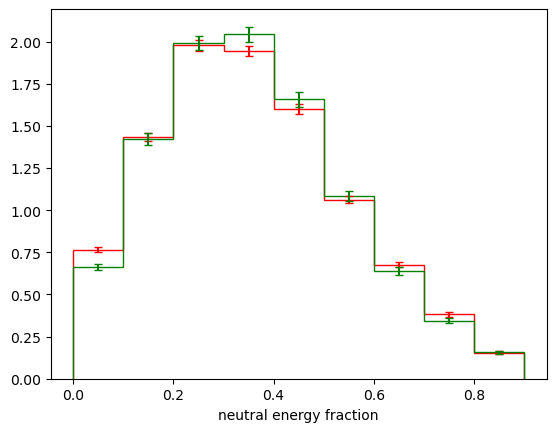

detector-level pT bin: 1


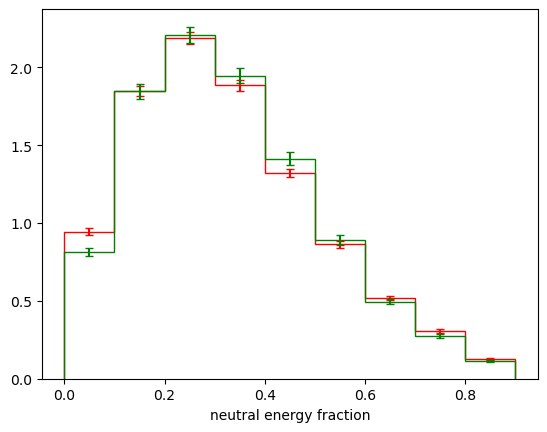

detector-level pT bin: 2


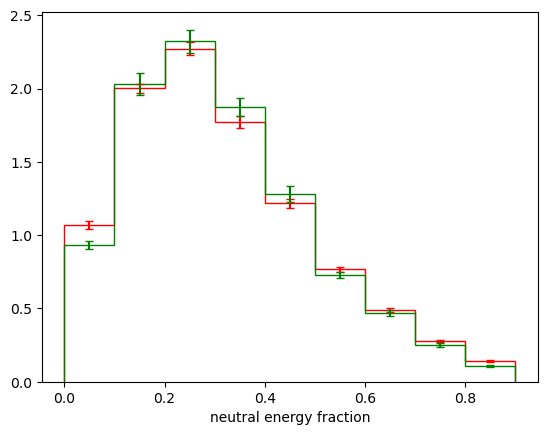

detector-level pT bin: 3


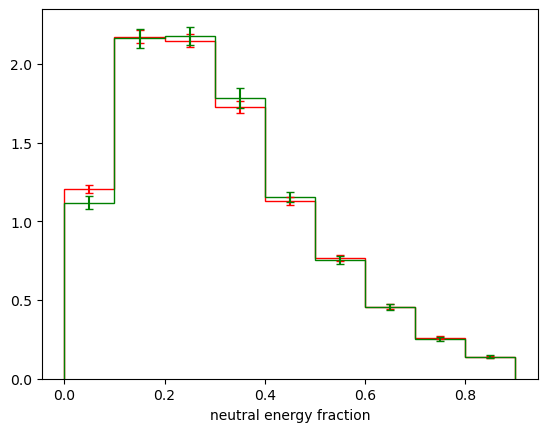

In [10]:
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs==1')
    y_temp_os, yerr_temp_os = calc_hist(df_temp_os['nefs'], weights=df_temp_os['ws'], bins=np.arange(0,1,0.1), density=True)[:-1]
    y_temp_ss, yerr_temp_ss = calc_hist(df_temp_ss['nefs'], weights=df_temp_ss['ws'], bins=np.arange(0,1,0.1), density=True)[:-1]
    print('detector-level pT bin:', i)
    plt.hist(df_temp_os['nefs'], weights=df_temp_os['ws'], bins=np.arange(0,1,0.1), density=True, color='r', histtype='step')
    plt.hist(df_temp_ss['nefs'], weights=df_temp_ss['ws'], bins=np.arange(0,1,0.1), density=True, color='g', histtype='step')
    plt.errorbar(np.arange(0.05,0.95,0.1), y_temp_os, yerr=yerr_temp_os, capsize=3, ls='none', color='r')
    plt.errorbar(np.arange(0.05,0.95,0.1), y_temp_ss, yerr=yerr_temp_ss, capsize=3, ls='none', color='g')
    plt.xlabel('neutral energy fraction')
    plt.show()

detector-level pT bin: 0


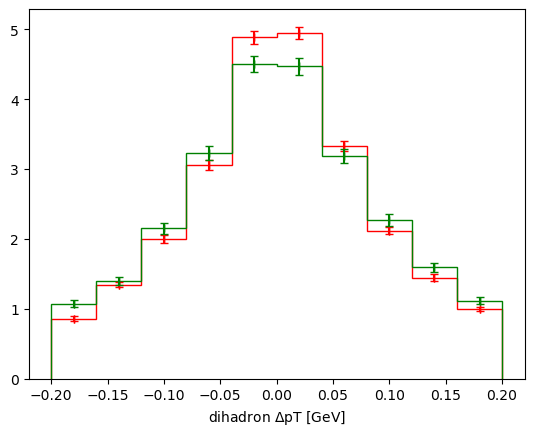

detector-level pT bin: 1


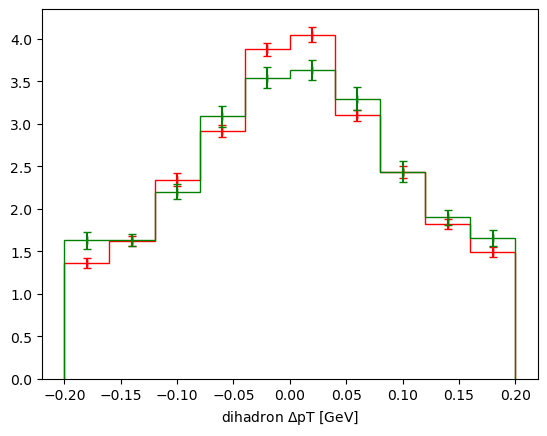

detector-level pT bin: 2


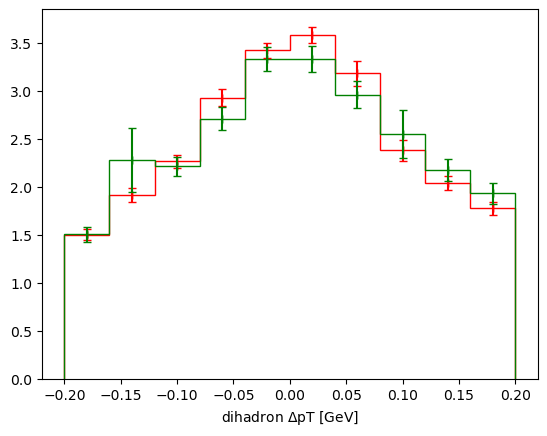

detector-level pT bin: 3


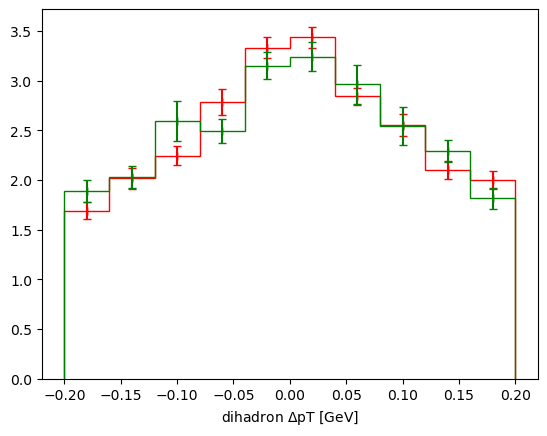

In [12]:
dpt_dihadron_array_os = []
sigma_dpt_dihadron_array_os = []
dpt_dihadron_array_ss = []
sigma_dpt_dihadron_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs==1')
    dpt_dihadron_os, sigma_dpt_dihadron_os = weighted_avg_and_std(df_temp_os['dpt_dihadron'], df_temp_os['w'])
    dpt_dihadron_ss, sigma_dpt_dihadron_ss = weighted_avg_and_std(df_temp_ss['dpt_dihadron'], df_temp_ss['w'])
    dpt_dihadron_array_os.append(dpt_dihadron_os)
    sigma_dpt_dihadron_array_os.append(sigma_dpt_dihadron_os)
    dpt_dihadron_array_ss.append(dpt_dihadron_ss)
    sigma_dpt_dihadron_array_ss.append(sigma_dpt_dihadron_ss)
    y_temp_os, yerr_temp_os, x = calc_hist(df_temp_os['dpt_dihadron'], weights=df_temp_os['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    y_temp_ss, yerr_temp_ss, x = calc_hist(df_temp_ss['dpt_dihadron'], weights=df_temp_ss['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('detector-level pT bin:', i)
    plt.hist(df_temp_os['dpt_dihadron'], weights=df_temp_os['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.hist(df_temp_ss['dpt_dihadron'], weights=df_temp_ss['w'], color='g', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_os/sum(y_temp_os), xerr=0, yerr=25*yerr_temp_os/sum(y_temp_os), color='r',ls='none',capsize=3)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_ss/sum(y_temp_ss), xerr=0, yerr=25*yerr_temp_ss/sum(y_temp_ss), color='g',ls='none',capsize=3)
    plt.xlabel('dihadron $\Delta$pT [GeV]')
    plt.ylim(bottom=0)
    plt.show()

detector-level pT bin: 0


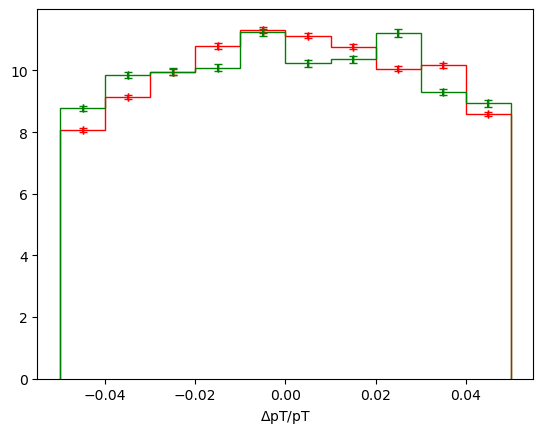

detector-level pT bin: 1


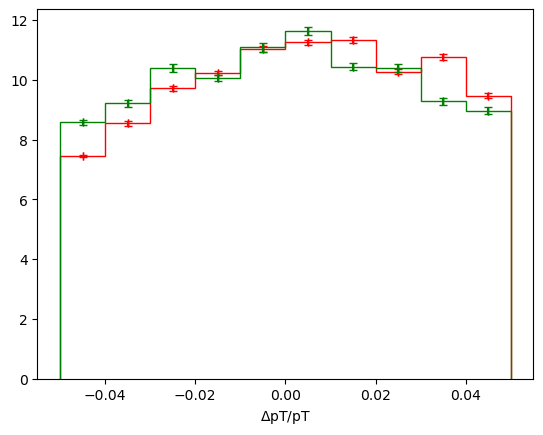

detector-level pT bin: 2


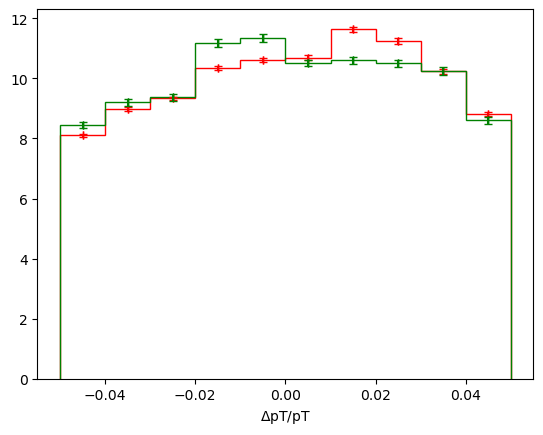

detector-level pT bin: 3


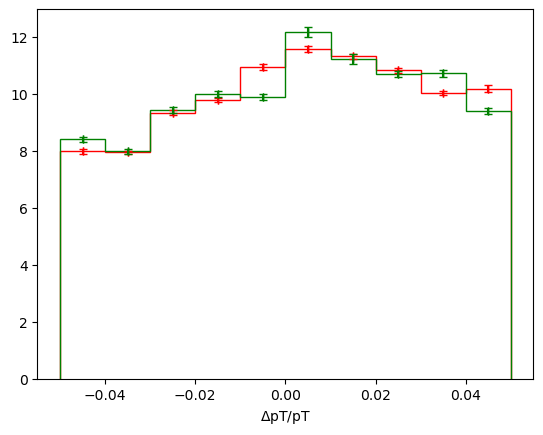

In [13]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)
    y_temp_os, yerr_temp_os, x = calc_hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], bins=np.arange(-0.05, 0.06, 0.01), density=True)
    y_temp_ss, yerr_temp_ss, x = calc_hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], bins=np.arange(-0.05, 0.06, 0.01), density=True)
    print('detector-level pT bin:', i)
    plt.hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], color='r', histtype='step', range=(-0.05,0.05), density=True)
    plt.hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], color='g', histtype='step', range=(-0.05,0.05), density=True)
    plt.errorbar(np.arange(-0.045, 0.055, 0.01), 100*y_temp_os/sum(y_temp_os), xerr=0, yerr=25*yerr_temp_os/sum(y_temp_os), color='r',ls='none',capsize=3)
    plt.errorbar(np.arange(-0.045, 0.055, 0.01), 100*y_temp_ss/sum(y_temp_ss), xerr=0, yerr=25*yerr_temp_ss/sum(y_temp_ss), color='g',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

detector-level pT bin: 0


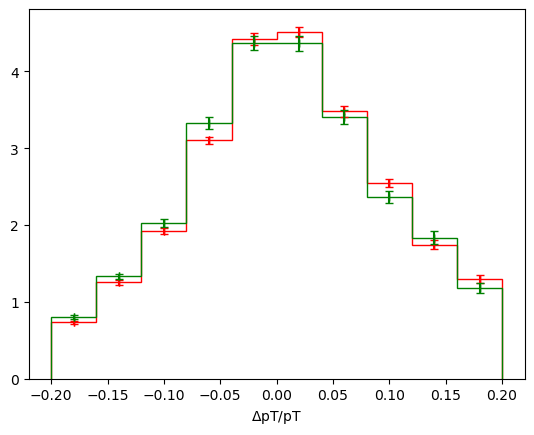

detector-level pT bin: 1


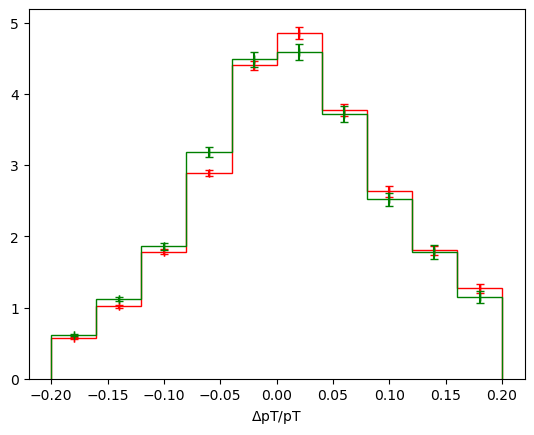

detector-level pT bin: 2


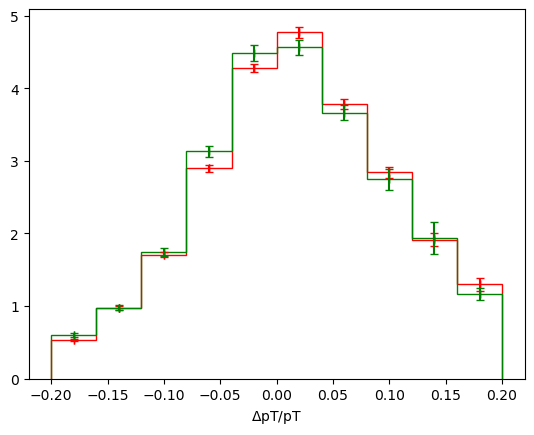

detector-level pT bin: 3


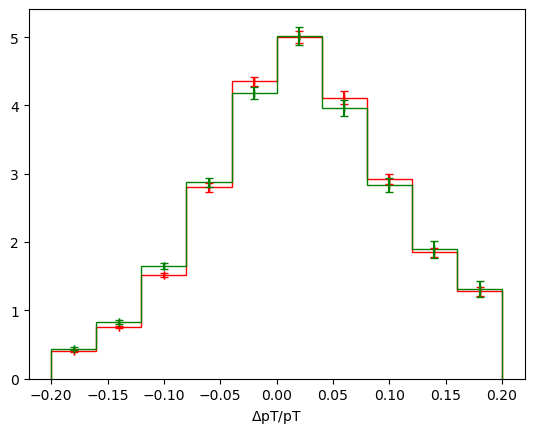

In [14]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)
    y_temp_os, yerr_temp_os, x = calc_hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    y_temp_ss, yerr_temp_ss, x = calc_hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('detector-level pT bin:', i)
    plt.hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], color='g', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_os/sum(y_temp_os), xerr=0, yerr=25*yerr_temp_os/sum(y_temp_os), color='r',ls='none',capsize=3)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_ss/sum(y_temp_ss), xerr=0, yerr=25*yerr_temp_ss/sum(y_temp_ss), color='g',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

In [19]:
nos_array1 = []
for j in range(0,4):
    df = applyCut(df_match_pts_array[j], 'bs==-1')
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    nos_array1.append(n)

In [20]:
nss_array1 = []
for j in range(0,4):
    df = applyCut(df_match_pts_array[j], 'bs==1')
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    nss_array1.append(n)

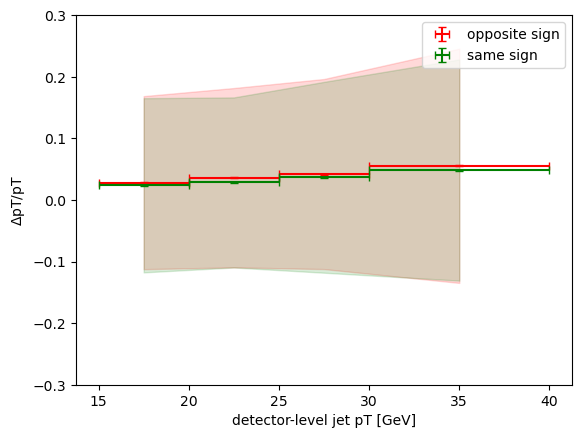

In [23]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=np.array(sigma_dpt_pt_array_os)/np.sqrt(np.array(nos_array1)), color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=np.array(sigma_dpt_pt_array_ss)/np.sqrt(np.array(nos_array1)), color='g', label='same sign', ls='none', capsize=3)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_os)-np.array(sigma_dpt_pt_array_os), np.array(dpt_pt_array_os)+np.array(sigma_dpt_pt_array_os), color='r', alpha=0.15)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(dpt_pt_array_ss)-np.array(sigma_dpt_pt_array_ss), np.array(dpt_pt_array_ss)+np.array(sigma_dpt_pt_array_ss), color='g', alpha=0.15)
plt.xlabel('detector-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.3,0.3)
plt.legend()

In [19]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]

In [20]:
spt_dihadron_array_os = []
sigma_spt_dihadron_array_os = []
spt_dihadron_array_ss = []
sigma_spt_dihadron_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pt_array[i], 'b==-1')
    df_temp_ss = applyCut(df_match_pt_array[i], 'b==1')
    spt_dihadron_os, sigma_spt_dihadron_os = weighted_avg_and_std(df_temp_os['spt_dihadron'], df_temp_os['w'])
    spt_dihadron_ss, sigma_spt_dihadron_ss = weighted_avg_and_std(df_temp_ss['spt_dihadron'], df_temp_ss['w'])
    spt_dihadron_array_os.append(spt_dihadron_os)
    sigma_spt_dihadron_array_os.append(sigma_spt_dihadron_os)
    spt_dihadron_array_ss.append(spt_dihadron_ss)
    sigma_spt_dihadron_array_ss.append(sigma_spt_dihadron_ss)

In [21]:
err_on_mean_os = []
for j in range(0,4):
    df = applyCut(df_match_pt_array[j], 'b==-1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['spt_dihadron'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_os.append(err2)

In [22]:
err_on_mean_ss = []
for j in range(0,4):
    df = applyCut(df_match_pt_array[j], 'b==1')
    w_array = np.unique(df['w'])
    err2 = 0
    variance_array_test = []
    for i in range(0, len(w_array)):
        variance = (weighted_avg_and_std(df['spt_dihadron'], df['w'])[1])**2/(df[df.w == w_array[i]].shape[0])
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2 += w**2*variance
    err_on_mean_ss.append(err2)

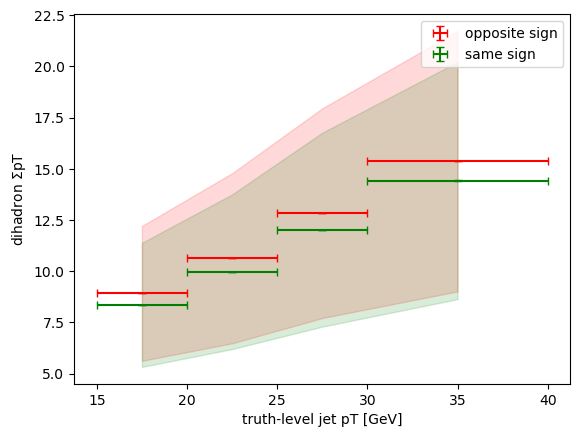

In [23]:
plt.errorbar([17.5, 22.5, 27.5, 35], spt_dihadron_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], spt_dihadron_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=err_on_mean_ss, color='g', label='same sign', ls='none', capsize=3)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(spt_dihadron_array_os)-np.array(sigma_spt_dihadron_array_os), np.array(spt_dihadron_array_os)+np.array(sigma_spt_dihadron_array_os), color='r', alpha=0.15)
plt.fill_between([17.5, 22.5, 27.5, 35], np.array(spt_dihadron_array_ss)-np.array(sigma_spt_dihadron_array_ss), np.array(spt_dihadron_array_ss)+np.array(sigma_spt_dihadron_array_ss), color='g', alpha=0.15)
plt.xlabel('truth-level jet pT [GeV]')
plt.ylabel('dihadron $\Sigma$pT')
#plt.ylim(-0.2,0.2)
plt.legend()

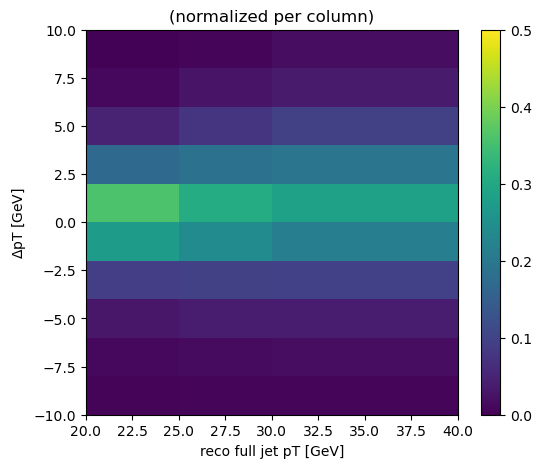

In [28]:
plt.figure(figsize=(6,5))
h,x,y = np.histogram2d(df_match['pts'], df_match['dpt'], weights=df_match['w'], bins=[np.arange(15,45,5),np.arange(-10,12,2)], density=True)
w = w_norm_per_xbin(h,[15,20,25,30,40],[-10,-8,-6,-4,-2,0,2,4,6,8,10])
plt.pcolormesh([15,20,25,30,40],[-10,-8,-6,-4,-2,0,2,4,6,8,10], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('$\Delta$pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(20,40)
plt.ylim(-10,10)
plt.clim(0,0.5)

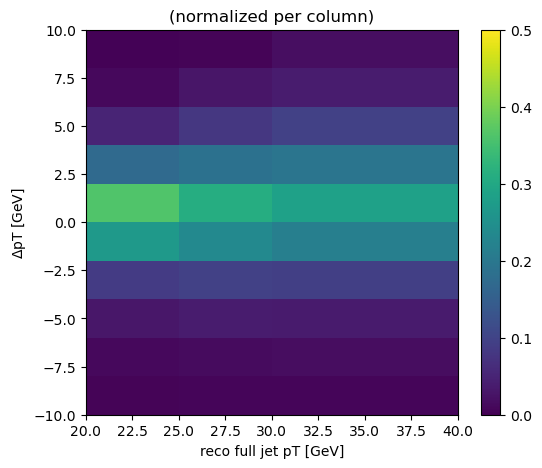

In [29]:
plt.figure(figsize=(6,5))
h,x,y = np.histogram2d(df_match[df_match.bs==-1]['pts'], df_match[df_match.bs==-1]['dpt'], weights=df_match[df_match.bs==-1]['w'], bins=[np.arange(15,45,5),np.arange(-10,12,2)], density=True)
w = w_norm_per_xbin(h,[15,20,25,30,40],[-10,-8,-6,-4,-2,0,2,4,6,8,10])
plt.pcolormesh([15,20,25,30,40],[-10,-8,-6,-4,-2,0,2,4,6,8,10], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('$\Delta$pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(20,40)
plt.ylim(-10,10)
plt.clim(0,0.5)

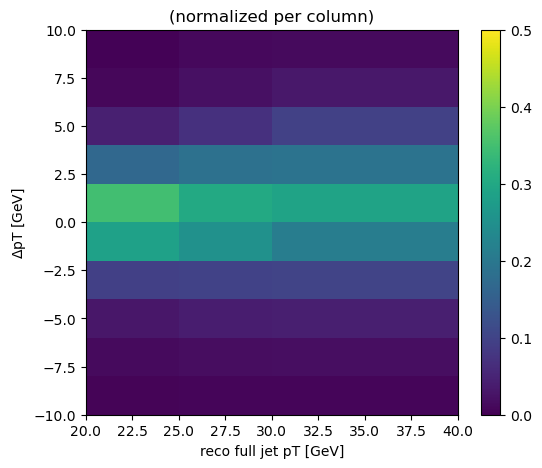

In [30]:
plt.figure(figsize=(6,5))
h,x,y = np.histogram2d(df_match[df_match.bs==1]['pts'], df_match[df_match.bs==1]['dpt'], weights=df_match[df_match.bs==1]['w'], bins=[np.arange(15,45,5),np.arange(-10,12,2)], density=True)
w = w_norm_per_xbin(h,[15,20,25,30,40],[-10,-8,-6,-4,-2,0,2,4,6,8,10])
plt.pcolormesh([15,20,25,30,40],[-10,-8,-6,-4,-2,0,2,4,6,8,10], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('$\Delta$pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(20,40)
plt.ylim(-10,10)
plt.clim(0,0.5)

With |vz| < 15 cm cut

In [20]:
df = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all0818_vz15_allreco.csv')

In [21]:
df_match = applyCut(df, 'pt>5 and b!=-9 and b!=0 and distance1 < 0.02 and distance2 < 0.02')

In [22]:
df_match.eval('dpt_pt = (pts-pt)/pt', inplace=True)

In [23]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

detector-level pT bin: 0


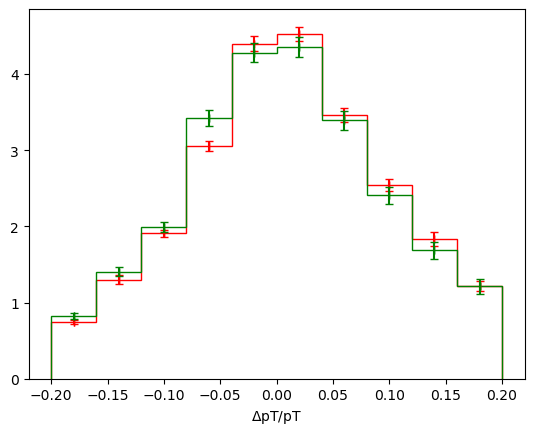

detector-level pT bin: 1


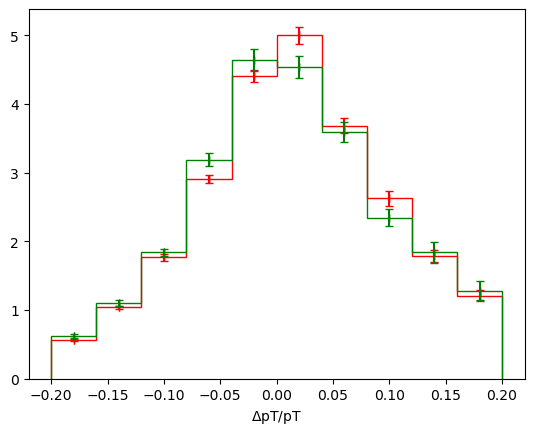

detector-level pT bin: 2


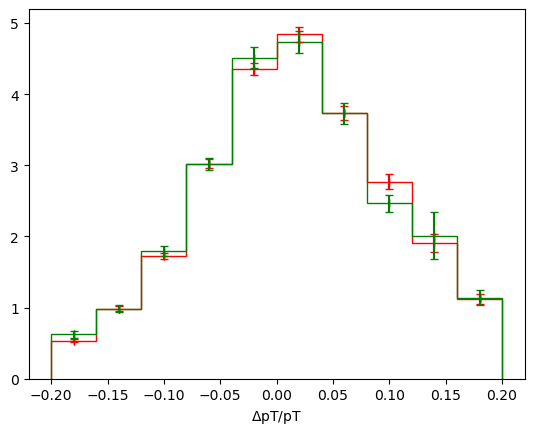

detector-level pT bin: 3


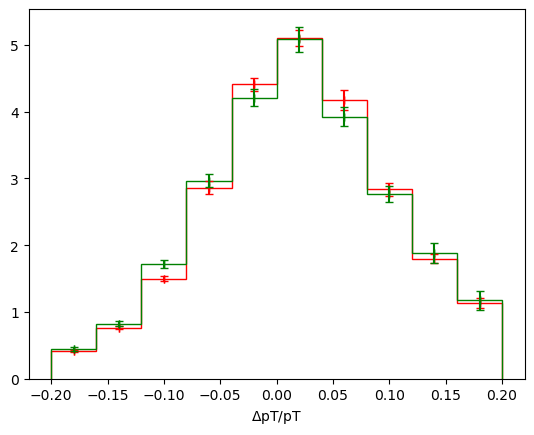

In [24]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)
    y_temp_os, yerr_temp_os, x = calc_hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    y_temp_ss, yerr_temp_ss, x = calc_hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('detector-level pT bin:', i)
    plt.hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], color='g', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_os/sum(y_temp_os), xerr=0, yerr=25*yerr_temp_os/sum(y_temp_os), color='r',ls='none',capsize=3)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_ss/sum(y_temp_ss), xerr=0, yerr=25*yerr_temp_ss/sum(y_temp_ss), color='g',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

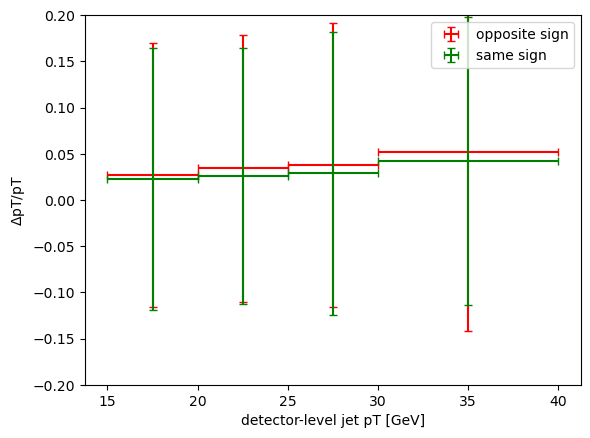

In [25]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_ss, color='g', label='same sign', ls='none', capsize=3)
plt.xlabel('detector-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.2,0.2)
plt.legend()